# Financial Fraud Detection: Risk-Flag Model

Data: `data/financial_fraud_detection_dataset.csv` (5,000 transactions, target `Fraudulent`).

Steps: cleaning, EDA, feature engineering, model comparison, final model, export of `dashboard_data.csv`.

Author: Akash Vaishnav, Zidio Development.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df2 = pd.read_csv("data/financial_fraud_detection_dataset.csv")

print(df2.shape)
print(df2.info())
print("Missing values:\n", df2.isnull().sum())
print("Duplicates:", df2.duplicated().sum())
print(df2["Fraudulent"].value_counts(normalize=True))
df2.head()

(5000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         5000 non-null   object 
 1   Customer_ID            5000 non-null   object 
 2   Transaction_Date       5000 non-null   object 
 3   Transaction_Amount     5000 non-null   float64
 4   Merchant_Category      5000 non-null   object 
 5   Payment_Method         5000 non-null   object 
 6   Device_Type            5000 non-null   object 
 7   Location               5000 non-null   object 
 8   Is_International       5000 non-null   int64  
 9   Previous_Transactions  5000 non-null   int64  
 10  Average_Spend          5000 non-null   float64
 11  Account_Age_Days       5000 non-null   int64  
 12  Suspicious_Keyword     5000 non-null   object 
 13  Fraudulent             5000 non-null   int64  
dtypes: float64(2), int64(4), object(8)
memory usa

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Suspicious_Keyword,Fraudulent
0,T100000,CUST3252,04-10-2023 07:45,37.54,Travel,PayPal,POS,Bengaluru,0,94,417.40,1492,No,0
1,T100001,CUST1630,26-09-2023 08:29,240.81,Utilities,PayPal,Mobile,Bengaluru,0,76,335.47,66,No,0
2,T100002,CUST7852,18-07-2023 15:54,105.34,Entertainment,Debit Card,Mobile,Bengaluru,0,60,432.03,216,No,0
3,T100003,CUST4892,16-10-2023 17:10,73.04,Utilities,NetBanking,Desktop,Kolkata,0,68,488.30,449,No,0
4,T100004,CUST8831,09-09-2023 00:46,13.57,Utilities,Credit Card,Desktop,Bengaluru,0,57,437.03,754,No,0


In [4]:
df2["Transaction_Date"] = pd.to_datetime(df2["Transaction_Date"],format="%d-%m-%Y %H:%M")
print(df2["Transaction_Date"].min(),df2["Transaction_Date"].max())
print(df2["Transaction_Date"].dtype)


2023-01-01 02:16:00 2024-02-21 15:34:00
datetime64[ns]


In [5]:
print(df2["Transaction_Date"].dt.to_period("M").value_counts().sort_index())

Transaction_Date
2023-01    363
2023-02    341
2023-03    348
2023-04    328
2023-05    389
2023-06    348
2023-07    392
2023-08    366
2023-09    369
2023-10    401
2023-11    379
2023-12    356
2024-01    356
2024-02    264
Freq: M, Name: count, dtype: int64


In [6]:
df2["Transaction_Date"].dt.to_period("M").value_counts().sum()

np.int64(5000)

In [7]:
cat_cols = ["Merchant_Category", "Payment_Method", "Device_Type", "Location", "Suspicious_Keyword"]
for col in cat_cols:
    print(f"\n{col}:")
    print(df2[col].value_counts())


Merchant_Category:
Merchant_Category
Food             684
Electronics      650
Entertainment    630
Grocery          629
Fashion          608
Health           606
Travel           599
Utilities        594
Name: count, dtype: int64

Payment_Method:
Payment_Method
NetBanking     1037
PayPal         1022
Debit Card     1008
Credit Card     972
UPI             961
Name: count, dtype: int64

Device_Type:
Device_Type
Desktop    1679
POS        1673
Mobile     1648
Name: count, dtype: int64

Location:
Location
Delhi        758
Mumbai       741
Hyderabad    725
Pune         722
Kolkata      713
Bengaluru    686
Chennai      655
Name: count, dtype: int64

Suspicious_Keyword:
Suspicious_Keyword
No     4740
Yes     260
Name: count, dtype: int64


In [8]:
num_cols = ["Transaction_Amount", "Average_Spend", "Previous_Transactions", "Account_Age_Days"]
print(df2[num_cols].describe().T.round(2))
print("Negative amounts:", (df2["Transaction_Amount"] < 0).sum())
print("Zero amounts:", (df2["Transaction_Amount"] == 0).sum())
print("Negative account age:", (df2["Account_Age_Days"] < 0).sum())

                        count     mean     std    min     25%      50%  \
Transaction_Amount     5000.0    79.18   78.96   0.00   22.36    55.46   
Average_Spend          5000.0   258.38  140.23  10.01  138.77   261.81   
Previous_Transactions  5000.0    99.41   57.02   1.00   50.00   100.00   
Account_Age_Days       5000.0  1011.16  568.63  30.00  530.00  1012.50   

                           75%      max  
Transaction_Amount      110.30   653.80  
Average_Spend           378.52   499.99  
Previous_Transactions   148.00   199.00  
Account_Age_Days       1496.00  1999.00  
Negative amounts: 0
Zero amounts: 2
Negative account age: 0


In [9]:
print(df2["Transaction_ID"].nunique(), df2["Customer_ID"].nunique())

5000 3847


In [10]:
print(pd.crosstab(df2["Suspicious_Keyword"], df2["Fraudulent"]))
print(df2.groupby("Suspicious_Keyword")["Fraudulent"].mean().round(3))

Fraudulent             0    1
Suspicious_Keyword           
No                  4381  359
Yes                  137  123
Suspicious_Keyword
No     0.076
Yes    0.473
Name: Fraudulent, dtype: float64


count
1    2895
2     778
3     148
4      25
5       1
Name: count, dtype: int64
Skewness: 1.9
0.90    181.16
0.95    240.53
0.99    364.59
Name: Transaction_Amount, dtype: float64


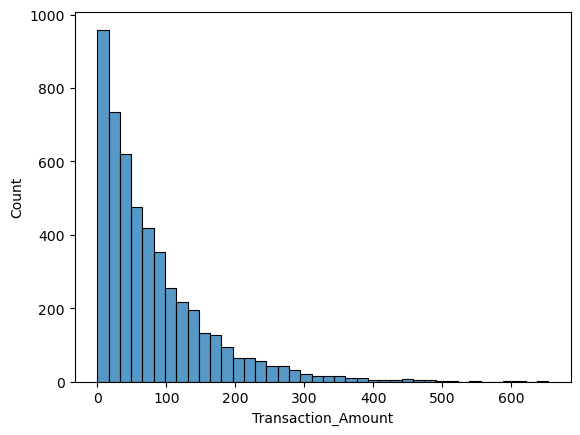

            Transaction_Amount  Average_Spend  Previous_Transactions  \
Fraudulent                                                             
0                        78.88         258.33                  99.69   
1                        81.99         258.86                  96.86   

            Account_Age_Days  
Fraudulent                    
0                    1009.57  
1                    1026.06  


In [5]:
import seaborn as sns 
repeat = df2["Customer_ID"].value_counts()
print(repeat.value_counts().sort_index())

top = repeat.index[0]
df2[df2["Customer_ID"] == top][["Customer_ID", "Average_Spend", "Account_Age_Days", "Previous_Transactions", "Fraudulent"]]

df2[df2["Transaction_Amount"] == 0]

print("Skewness:", round(df2["Transaction_Amount"].skew(), 2))
print(df2["Transaction_Amount"].quantile([0.90, 0.95, 0.99]).round(2))
sns.histplot(df2["Transaction_Amount"], bins=40)
plt.show()

print(df2.groupby("Fraudulent")[["Transaction_Amount", "Average_Spend", "Previous_Transactions", "Account_Age_Days"]].mean().round(2))

In [6]:
print(repeat.head())
print("Top customer ID:", repeat.index[0], "appears", repeat.iloc[0], "times")

Customer_ID
CUST8944    5
CUST4556    4
CUST3443    4
CUST4691    4
CUST8885    4
Name: count, dtype: int64
Top customer ID: CUST8944 appears 5 times


In [7]:
top = repeat.index[0]
df2[df2["Customer_ID"] == top][["Customer_ID", "Average_Spend", "Account_Age_Days", "Previous_Transactions", "Fraudulent"]]

,Customer_ID,Average_Spend,Account_Age_Days,Previous_Transactions,Fraudulent
268,CUST8944,181.01,864,189,1
1242,CUST8944,12.87,1090,192,0
2941,CUST8944,298.62,111,48,0
3607,CUST8944,251.96,898,123,0
4690,CUST8944,454.60,1017,68,0


In [10]:
df2["Transaction_Date"] = pd.to_datetime(df2["Transaction_Date"], format="%d-%m-%Y %H:%M")
print(df2["Transaction_Date"].dtype)

datetime64[ns]


In [12]:
print(df2.groupby("Is_International")["Fraudulent"].agg(["mean", "count"]).round(3))

df2["Hour"] = df2["Transaction_Date"].dt.hour
df2["Time_Block"] = pd.cut(df2["Hour"], [-1, 5, 11, 17, 23],
                           labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])

print(df2.groupby("Time_Block", observed=True)["Fraudulent"].agg(["mean", "count"]).round(3))

                  mean  count
Is_International             
0                 0.07   4559
1                 0.37    441
                    mean  count
Time_Block                     
Night (0-5)        0.256   1222
Morning (6-11)     0.048   1269
Afternoon (12-17)  0.043   1264
Evening (18-23)    0.043   1245


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = "data/financial_fraud_detection_dataset.csv"
df2 = pd.read_csv(path)
df2["Transaction_Date"] = pd.to_datetime(df2["Transaction_Date"], format="%d-%m-%Y %H:%M")
print(df2.shape)

(5000, 14)


In [3]:
df2["Hour"] = df2["Transaction_Date"].dt.hour
df2["Is_Night"] = (df2["Hour"] <= 5).astype(int)
df2["Weekday"] = df2["Transaction_Date"].dt.dayofweek 
df2["Is_Weekend"] = (df2["Weekday"] >= 5).astype(int)
df2["Month"] = df2["Transaction_Date"].dt.month

df2["Log_Amount"] = np.log1p(df2["Transaction_Amount"])
df2["Suspicious_Keyword"] = df2["Suspicious_Keyword"].map({"No": 0, "Yes": 1})

print(df2[["Hour", "Is_Night", "Weekday", "Is_Weekend", "Month", "Log_Amount", "Suspicious_Keyword"]].head())
print(df2["Suspicious_Keyword"].value_counts())

   Hour  Is_Night  Weekday  Is_Weekend  Month  Log_Amount  Suspicious_Keyword
0     7         0        2           0     10    3.651697                   0
1     8         0        1           0      9    5.488152                   0
2    15         0        1           0      7    4.666642                   0
3    17         0        0           0     10    4.304605                   0
4     0         1        5           1      9    2.678965                   0
Suspicious_Keyword
0    4740
1     260
Name: count, dtype: int64


In [4]:
from scipy.stats import chi2_contingency

for col in ["Weekday", "Month", "Is_Weekend"]:
    p = chi2_contingency(pd.crosstab(df2[col], df2["Fraudulent"]))[1]
    print(col, "p-value =", round(p, 3))

Weekday p-value = 0.257
Month p-value = 0.544
Is_Weekend p-value = 0.645


In [5]:
features = ["Is_Night", "Is_International", "Suspicious_Keyword",
            "Log_Amount", "Average_Spend", "Previous_Transactions", "Account_Age_Days"]

X = df2[features]
y = df2["Fraudulent"]
print(X.shape, y.shape)
print(X.isnull().sum().sum(), "missing values")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Fraud rate:", round(y_train.mean(), 4))
print("Test: ", X_test.shape, "Fraud rate:", round(y_test.mean(), 4))

(5000, 7) (5000,)
0 missing values
Train: (3750, 7) Fraud rate: 0.0965
Test:  (1250, 7) Fraud rate: 0.096


In [6]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            min_samples_leaf=5, random_state=42, n_jobs=-1),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy,0.00,0.000,0.000,0.500,0.096
1,Logistic Regression,0.27,1.000,0.426,0.891,0.410
2,Random Forest,0.34,0.575,0.427,0.886,0.387


In [7]:
df2["Risk_Flags"] = df2["Is_Night"] + df2["Is_International"] + df2["Suspicious_Keyword"]
print(df2.groupby("Risk_Flags")["Fraudulent"].agg(["mean", "sum", "count"]).round(3))

             mean  sum  count
Risk_Flags                   
0           0.000    1   3278
1           0.242  370   1528
2           0.556  104    187
3           1.000    7      7


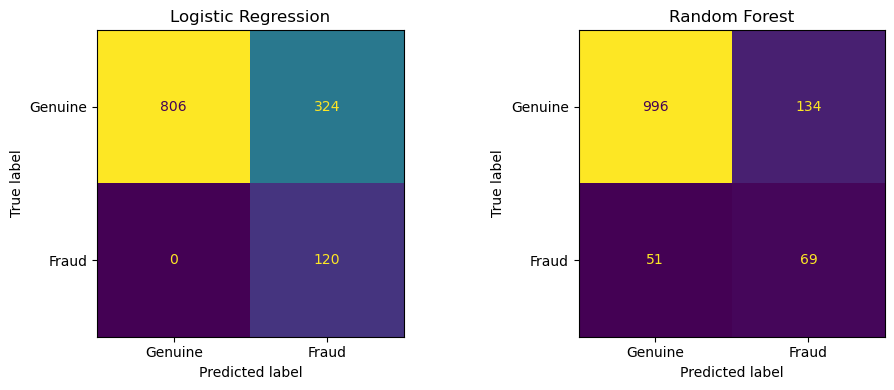

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    pred = models[name].predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Genuine", "Fraud"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [10]:
import numpy as np
from sklearn.metrics import precision_recall_curve

rf_proba = models["Random Forest"].predict_proba(X_test)[:, 1]
lr_proba = models["Logistic Regression"].predict_proba(X_test)[:, 1]

rows = []
for name, proba in [("Logistic Regression", lr_proba), ("Random Forest", rf_proba)]:
    for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
        pred = (proba >= t).astype(int)
        rows.append({
            "Model": name, "Threshold": t,
            "Flagged": pred.sum(),
            "Caught": ((pred == 1) & (y_test == 1)).sum(),
            "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
            "Recall": round(recall_score(y_test, pred), 3),
            "F1": round(f1_score(y_test, pred), 3),
        })

pd.DataFrame(rows)

,Model,Threshold,Flagged,Caught,Precision,Recall,F1
0,Logistic Regression,0.2,444,120,0.270,1.000,0.426
1,Logistic Regression,0.3,444,120,0.270,1.000,0.426
2,Logistic Regression,0.4,444,120,0.270,1.000,0.426
3,Logistic Regression,0.5,444,120,0.270,1.000,0.426
4,Logistic Regression,0.6,444,120,0.270,1.000,0.426
5,Logistic Regression,0.7,295,90,0.305,0.750,0.434
6,Random Forest,0.2,442,118,0.267,0.983,0.420
7,Random Forest,0.3,417,114,0.273,0.950,0.425
8,Random Forest,0.4,328,95,0.290,0.792,0.424
9,Random Forest,0.5,203,69,0.340,0.575,0.427


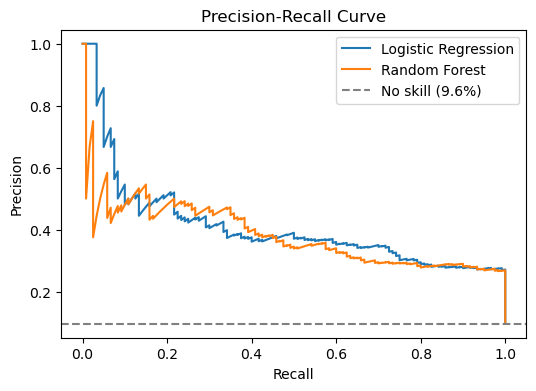

In [11]:
plt.figure(figsize=(6, 4))
for name, proba in [("Logistic Regression", lr_proba), ("Random Forest", rf_proba)]:
    p, r, _ = precision_recall_curve(y_test, proba)
    plt.plot(r, p, label=name)
plt.axhline(y_test.mean(), color="grey", linestyle="--", label="No skill (9.6%)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [12]:
!pip install xgboost

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Random Forest": models["Random Forest"],
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                             eval_metric="logloss", random_state=42),
}

rows = []
for name, model in cv_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "average_precision", "recall", "precision", "f1"])
    rows.append({
        "Model": name,
        "ROC-AUC": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}",
        "PR-AUC": f"{scores['test_average_precision'].mean():.3f} ± {scores['test_average_precision'].std():.3f}",
        "Recall": f"{scores['test_recall'].mean():.3f}",
        "Precision": f"{scores['test_precision'].mean():.3f}",
        "F1": f"{scores['test_f1'].mean():.3f}",
    })

pd.DataFrame(rows)

,Model,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Logistic Regression,0.902 ± 0.009,0.447 ± 0.042,0.997,0.283,0.441
1,Random Forest,0.897 ± 0.011,0.410 ± 0.051,0.610,0.359,0.451
2,XGBoost,0.892 ± 0.010,0.388 ± 0.034,0.928,0.287,0.438


In [14]:
import pandas as pd
lr = models["Logistic Regression"]
coefs = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=X_train.columns)
print("Logistic Regression coefficients:")
print(coefs.sort_values(ascending=False).round(3))
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X_train.columns)
print("\nRandom Forest importance:")
print(imp.sort_values(ascending=False).round(3))

Logistic Regression coefficients:
Is_Night                 1.884
Is_International         1.301
Suspicious_Keyword       1.045
Average_Spend            0.110
Log_Amount               0.098
Account_Age_Days        -0.018
Previous_Transactions   -0.049
dtype: float64

Random Forest importance:
Is_Night                 0.335
Is_International         0.201
Suspicious_Keyword       0.135
Log_Amount               0.089
Average_Spend            0.084
Account_Age_Days         0.078
Previous_Transactions    0.078
dtype: float64


Suspicious_Keyword       0.147
Is_International         0.119
Is_Night                 0.090
Previous_Transactions    0.028
Log_Amount               0.003
Account_Age_Days        -0.001
Average_Spend           -0.013
dtype: float64


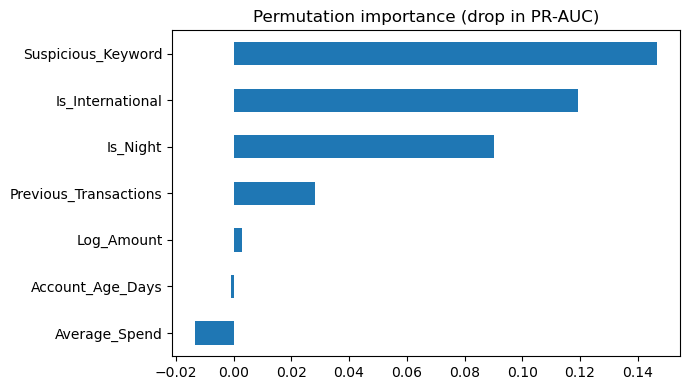

In [15]:
from sklearn.inspection import permutation_importance

rf = models["Random Forest"]
pi = permutation_importance(rf, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=42)

perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(perm.round(3))

perm.sort_values().plot(kind="barh", figsize=(7, 4), title="Permutation importance (drop in PR-AUC)")
plt.tight_layout()
plt.show()

In [16]:
three = ["Is_Night", "Is_International", "Suspicious_Keyword"]

rows = []
for label, cols in [("All 7 features", list(X_train.columns)), ("3 risk flags only", three)]:
    for name in ["Logistic Regression", "Random Forest"]:
        s = cross_validate(models[name], X_train[cols], y_train, cv=cv,
                           scoring=["roc_auc", "average_precision"])
        rows.append({"Features": label, "Model": name,
                     "ROC-AUC": round(s["test_roc_auc"].mean(), 3),
                     "PR-AUC": f"{s['test_average_precision'].mean():.3f} ± {s['test_average_precision'].std():.3f}"})

pd.DataFrame(rows)

,Features,Model,ROC-AUC,PR-AUC
0,All 7 features,Logistic Regression,0.902,0.447 ± 0.042
1,All 7 features,Random Forest,0.897,0.410 ± 0.051
2,3 risk flags only,Logistic Regression,0.897,0.413 ± 0.023
3,3 risk flags only,Random Forest,0.897,0.393 ± 0.024


In [17]:
!pip install imbalanced-learn

In [18]:
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

options = {
    "LR + class weights": imb_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "LR + no balancing":  imb_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "LR + SMOTE":         imb_pipeline(StandardScaler(), SMOTE(random_state=42), LogisticRegression(max_iter=1000)),
    "RF + class weights": RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=5, random_state=42, n_jobs=-1),
    "RF + no balancing":  RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "RF + SMOTE":         imb_pipeline(SMOTE(random_state=42), RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)),
}

rows = []
for name, model in options.items():
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "average_precision", "recall", "precision", "f1"])
    rows.append({"Setup": name,
                 "ROC-AUC": round(s["test_roc_auc"].mean(), 3),
                 "PR-AUC": round(s["test_average_precision"].mean(), 3),
                 "Recall": round(s["test_recall"].mean(), 3),
                 "Precision": round(s["test_precision"].mean(), 3),
                 "F1": round(s["test_f1"].mean(), 3)})

pd.DataFrame(rows)


,Setup,ROC-AUC,PR-AUC,Recall,Precision,F1
0,LR + class weights,0.902,0.447,0.997,0.283,0.441
1,LR + no balancing,0.898,0.432,0.237,0.594,0.337
2,LR + SMOTE,0.899,0.444,0.997,0.283,0.441
3,RF + class weights,0.897,0.410,0.610,0.359,0.451
4,RF + no balancing,0.898,0.409,0.086,0.471,0.144
5,RF + SMOTE,0.805,0.263,0.652,0.245,0.356


In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score

three = ["Is_Night", "Is_International", "Suspicious_Keyword"]
final_model = make_pipeline(StandardScaler(),
                            LogisticRegression(class_weight="balanced", max_iter=1000))

oof = cross_val_predict(final_model, X_train[three], y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in sorted(set(oof.round(3))):
    pred = (oof >= t - 1e-9).astype(int)
    if pred.sum() == 0:
        continue
    rows.append({"Threshold": t, "Flagged": pred.sum(),
                 "Precision": round(precision_score(y_train, pred), 3),
                 "Recall": round(recall_score(y_train, pred), 3),
                 "F1": round(f1_score(y_train, pred), 3),
                 "F2": round(fbeta_score(y_train, pred, beta=2), 3)})
pd.DataFrame(rows)

,Threshold,Flagged,Precision,Recall,F1,F2
0,0.025,3247,0.111,0.997,0.200,0.384
1,0.026,3247,0.111,0.997,0.200,0.384
2,0.028,2281,0.158,0.997,0.273,0.484
3,0.030,1792,0.201,0.997,0.335,0.557
4,0.031,1278,0.282,0.997,0.440,0.662
5,0.684,1126,0.288,0.895,0.435,0.629
6,0.691,1126,0.288,0.895,0.435,0.629
7,0.697,827,0.311,0.710,0.432,0.565
8,0.700,827,0.311,0.710,0.432,0.565
9,0.702,664,0.337,0.619,0.437,0.530


ROC-AUC: 0.907
PR-AUC : 0.453
              precision    recall  f1-score   support

     Genuine       1.00      0.71      0.83      1130
       Fraud       0.27      1.00      0.43       120

    accuracy                           0.74      1250
   macro avg       0.64      0.86      0.63      1250
weighted avg       0.93      0.74      0.79      1250



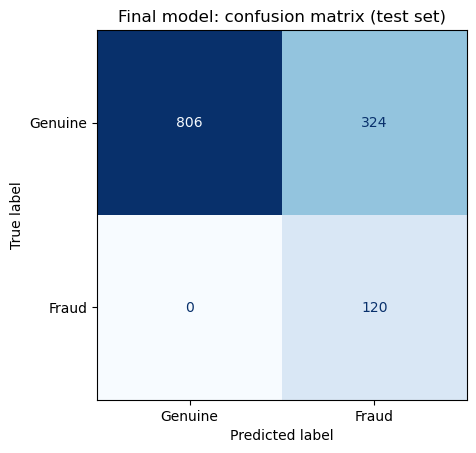

['final_model.joblib']

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

final_model.fit(X_train[three], y_train)
proba = final_model.predict_proba(X_test[three])[:, 1]
pred = (proba >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))
print(classification_report(y_test, pred, target_names=["Genuine", "Fraud"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Genuine", "Fraud"],
                                        cmap="Blues", colorbar=False)
plt.title("Final model: confusion matrix (test set)")
plt.show()

# save the model for the dashboard and report
import joblib
joblib.dump(final_model, "final_model.joblib")

In [26]:
dash = df2.copy()

dash["Fraud_Probability"] = final_model.predict_proba(dash[three])[:, 1].round(3)
dash["Predicted_Fraud"] = (dash["Fraud_Probability"] >= 0.5).astype(int)
dash["Risk_Flags"] = dash["Is_Night"] + dash["Is_International"] + dash["Suspicious_Keyword"]
dash["Time_Block"] = pd.cut(dash["Hour"], [-1, 5, 11, 17, 23],
                            labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
dash["Data_Split"] = "Train"
dash.loc[X_test.index, "Data_Split"] = "Test"
dash["Year_Month"] = dash["Transaction_Date"].dt.to_period("M").astype(str)

cols = ["Transaction_ID", "Transaction_Date", "Year_Month", "Hour", "Time_Block",
        "Transaction_Amount", "Merchant_Category", "Payment_Method", "Device_Type", "Location",
        "Is_International", "Suspicious_Keyword", "Is_Night", "Risk_Flags",
        "Fraud_Probability", "Predicted_Fraud", "Fraudulent", "Data_Split"]

out = "dashboard_data.csv"
dash[cols].to_csv(out, index=False)

print(dash[cols].shape)
print(dash["Data_Split"].value_counts().to_dict())

import os
print(os.path.exists(out), round(os.path.getsize(out) / 1024), "KB")
dash[cols].head()

(5000, 18)
{'Train': 3750, 'Test': 1250}
True 569 KB


,Transaction_ID,Transaction_Date,Year_Month,Hour,Time_Block,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Suspicious_Keyword,Is_Night,Risk_Flags,Fraud_Probability,Predicted_Fraud,Fraudulent,Data_Split
0,T100000,2023-10-04 07:45:00,2023-10,7,Morning (6-11),37.54,Travel,PayPal,POS,Bengaluru,0,0,0,0,0.028,0,0,Train
1,T100001,2023-09-26 08:29:00,2023-09,8,Morning (6-11),240.81,Utilities,PayPal,Mobile,Bengaluru,0,0,0,0,0.028,0,0,Train
2,T100002,2023-07-18 15:54:00,2023-07,15,Afternoon (12-17),105.34,Entertainment,Debit Card,Mobile,Bengaluru,0,0,0,0,0.028,0,0,Train
3,T100003,2023-10-16 17:10:00,2023-10,17,Afternoon (12-17),73.04,Utilities,NetBanking,Desktop,Kolkata,0,0,0,0,0.028,0,0,Test
4,T100004,2023-09-09 00:46:00,2023-09,0,Night (0-5),13.57,Utilities,Credit Card,Desktop,Bengaluru,0,0,1,1,0.695,1,0,Test


In [27]:
dash["Time_Block_Order"] = pd.cut(dash["Hour"], [-1, 5, 11, 17, 23], labels=[1, 2, 3, 4]).astype(int)
dash["International"] = dash["Is_International"].map({0: "Domestic", 1: "International"})
dash["Keyword_Flag"] = dash["Suspicious_Keyword"].map({0: "No keyword", 1: "Keyword"})
dash["Outcome"] = np.select(
    [(dash["Predicted_Fraud"] == 1) & (dash["Fraudulent"] == 1),
     (dash["Predicted_Fraud"] == 1) & (dash["Fraudulent"] == 0),
     (dash["Predicted_Fraud"] == 0) & (dash["Fraudulent"] == 1)],
    ["Caught fraud", "False alarm", "Missed fraud"], default="Correct genuine")

cols2 = cols + ["Time_Block_Order", "International", "Keyword_Flag", "Outcome"]
dash[cols2].to_csv(out, index=False)
print(dash[cols2].shape)
print(dash["Outcome"].value_counts().to_dict())

(5000, 22)
{'Correct genuine': 3277, 'False alarm': 1241, 'Caught fraud': 481, 'Missed fraud': 1}
